# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import S2LookingDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [5]:
dataset_config = {
    "data_dir" : "/home/dragik/data/FAIR_EO/s2looking/S2Looking/train/",
}
dataset = S2LookingDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 3500


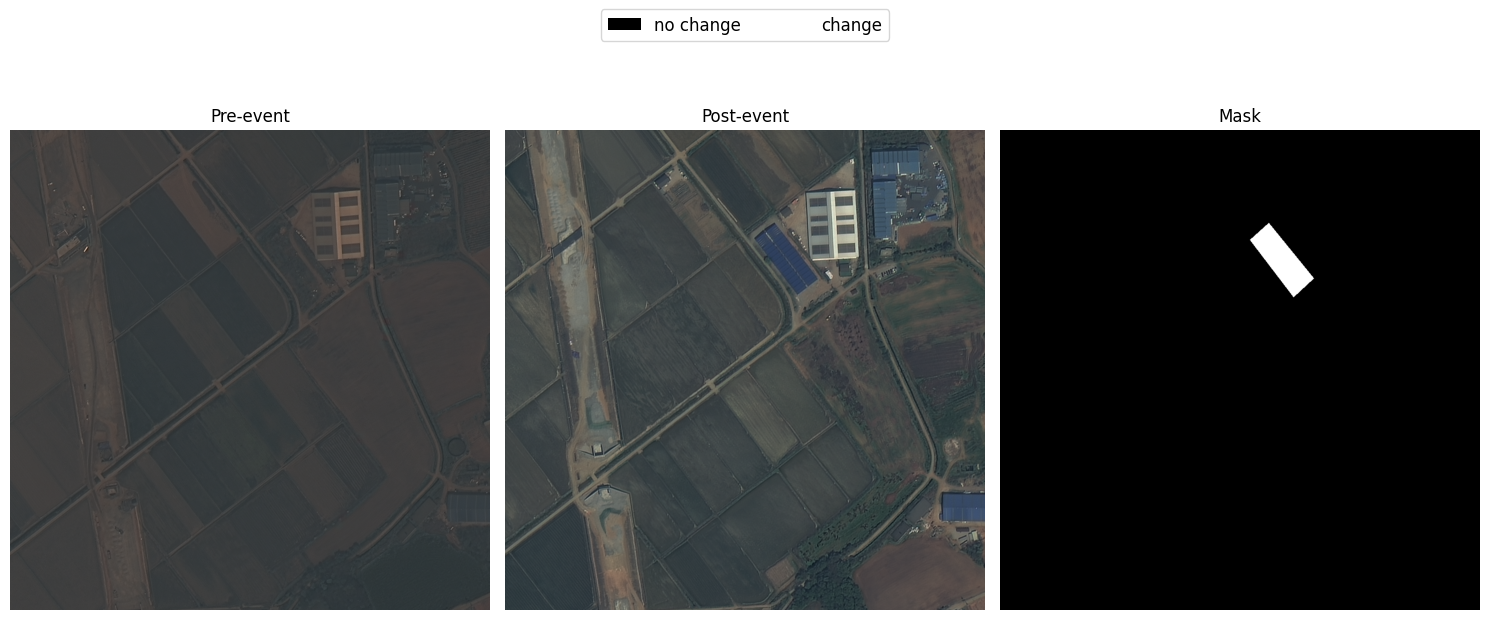

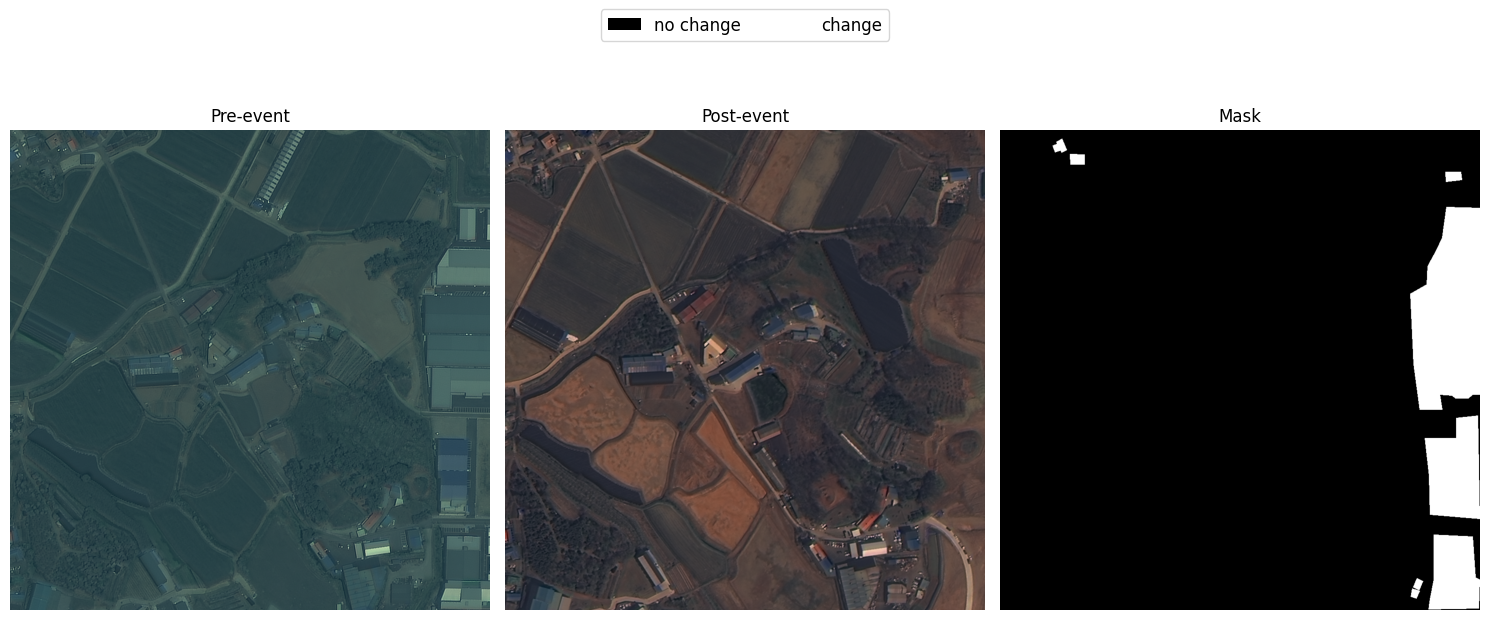

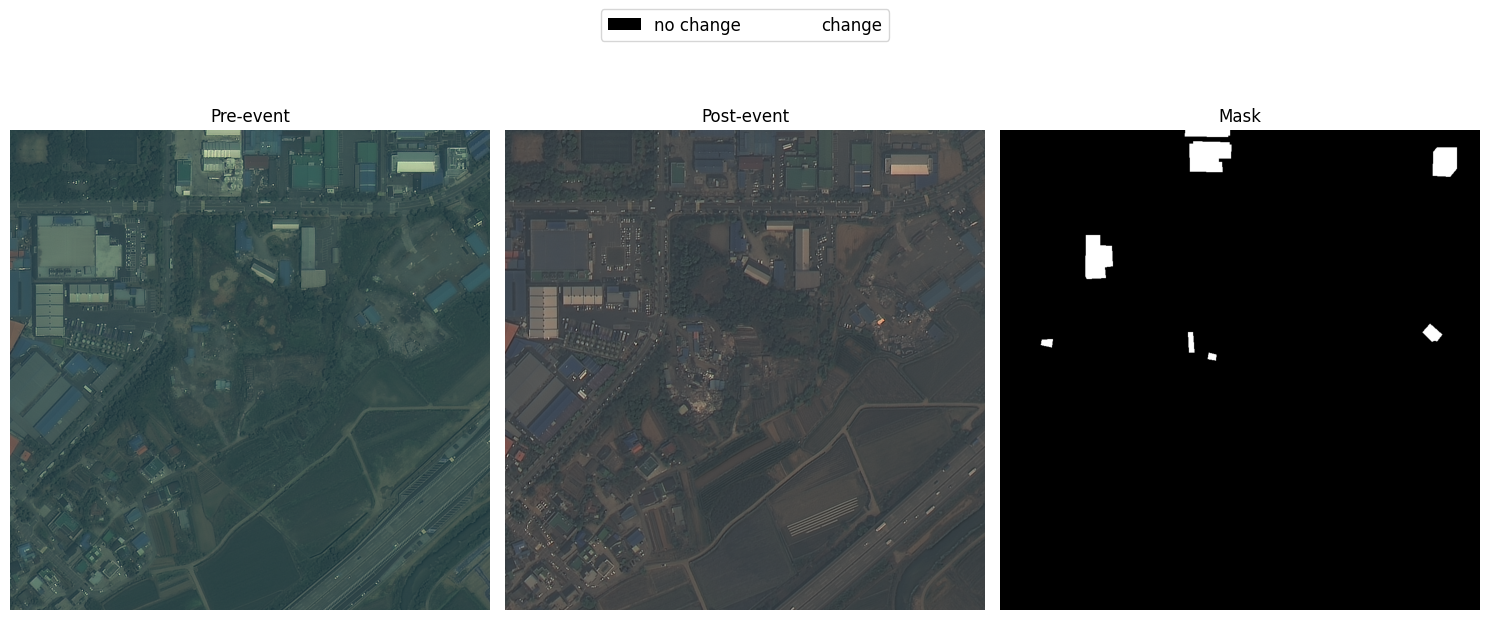

In [10]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(22);

In [11]:
dataset.data_distribution_table()

,Number of pixels
no change,3.623286e+09
change,4.672961e+07


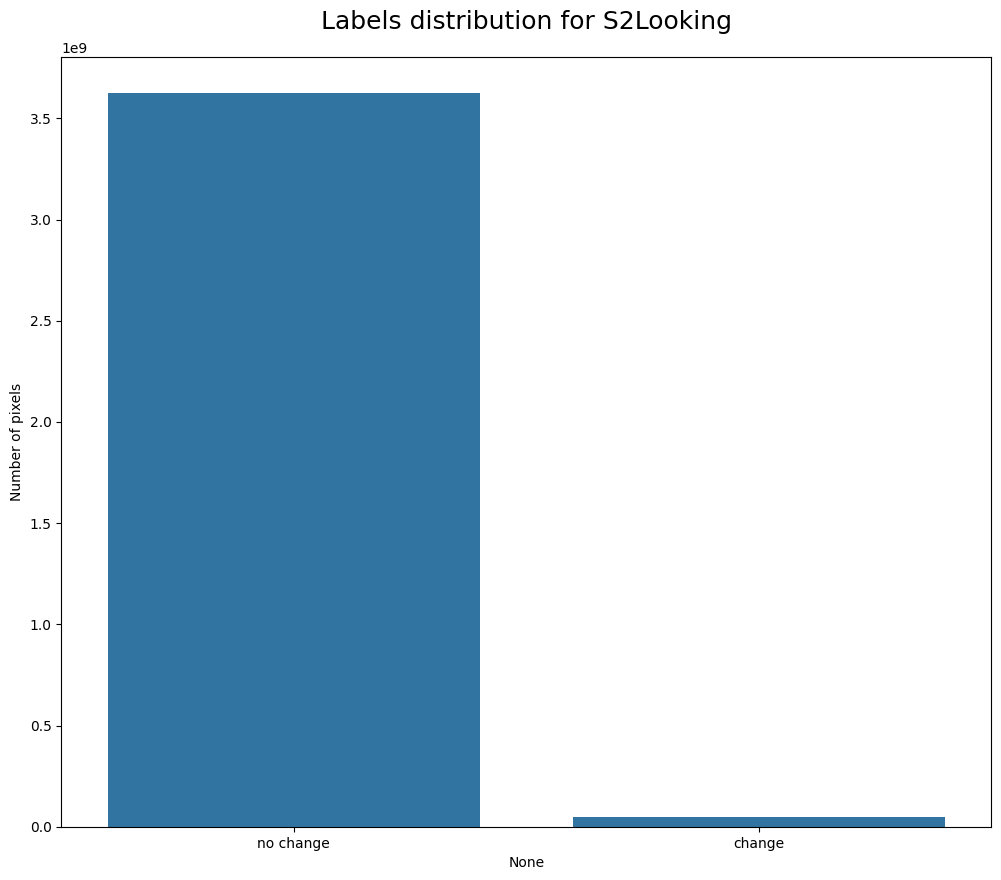

In [12]:
dataset.data_distribution_barchart();

## Load training and test data

In [6]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/s2looking/S2Looking/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = S2LookingDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "/home/dragik/data/FAIR_EO/s2looking/S2Looking/val/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = S2LookingDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(3500, 500)

## Create the model

In [7]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/s2looking"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [8]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-26 12:58:54,785 INFO Starting training.
training: 100%|██████████| 110/110 [26:12<00:00, 14.29s/it]
2026-01-26 13:25:07,251 INFO epoch: 1, loss:  0.23377
testing on train set: 100%|██████████| 110/110 [26:41<00:00, 14.56s/it]
2026-01-26 13:51:49,919 INFO Accuracy:0.9819259163992745, Accuracy per Class:[0.9724977  0.99135413], Precision Micro:0.9826451370932885, Precision Macro:0.4943082162039406, Precision Weighted:0.9742748244566076, Precision per Class:[0.98272108 0.00589536], Recall Micro:0.9808512257489035, Recall Macro:0.49472935043236976, Recall Weighted:0.9808512257489036, Recall per Class:[9.89405794e-01 5.29067691e-05], F1_score Micro:0.9817473619344969, F1_score Macro:0.4930784888356703, F1_score Weighted:0.9775269843773389, F1_score per Class:[9.86052105e-01 1.04872381e-04], IOU:0.964149097418143, IOU mean:0.4862701923780168, IOU per Class:[9.72487946e-01 5.24389401e-05]
training: 100%|██████████| 110/110 [26:57<00:00, 14.71s/it]
2026-01-26 14:18:47,490 INFO epoch: 2

## Predictions

2026-01-28 07:46:53,078 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/s2looking/checkpoint.pth.tar
2026-01-28 07:46:53,438 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/s2looking/checkpoint.pth.tar at epoch 51


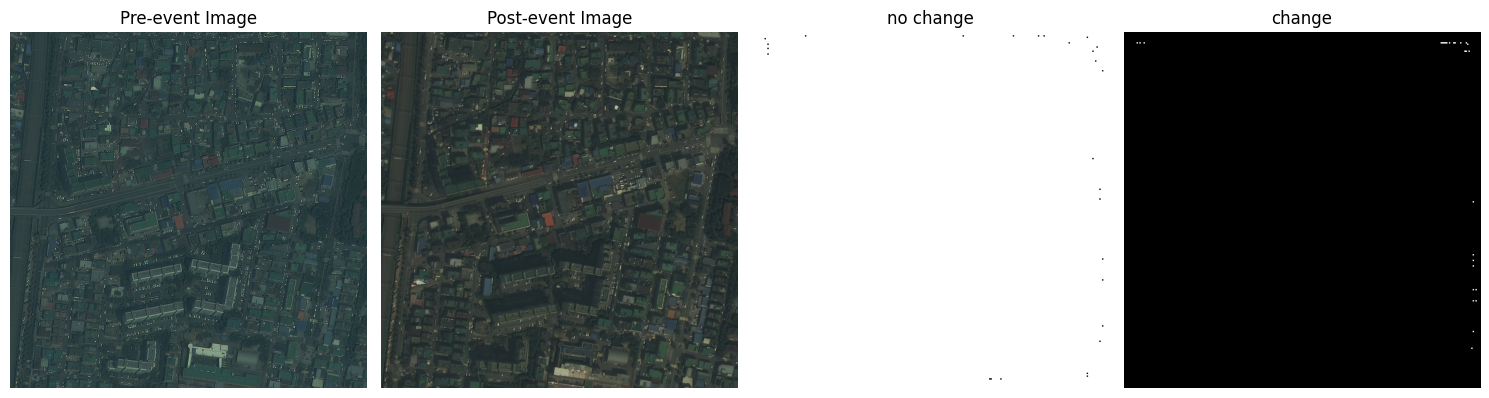

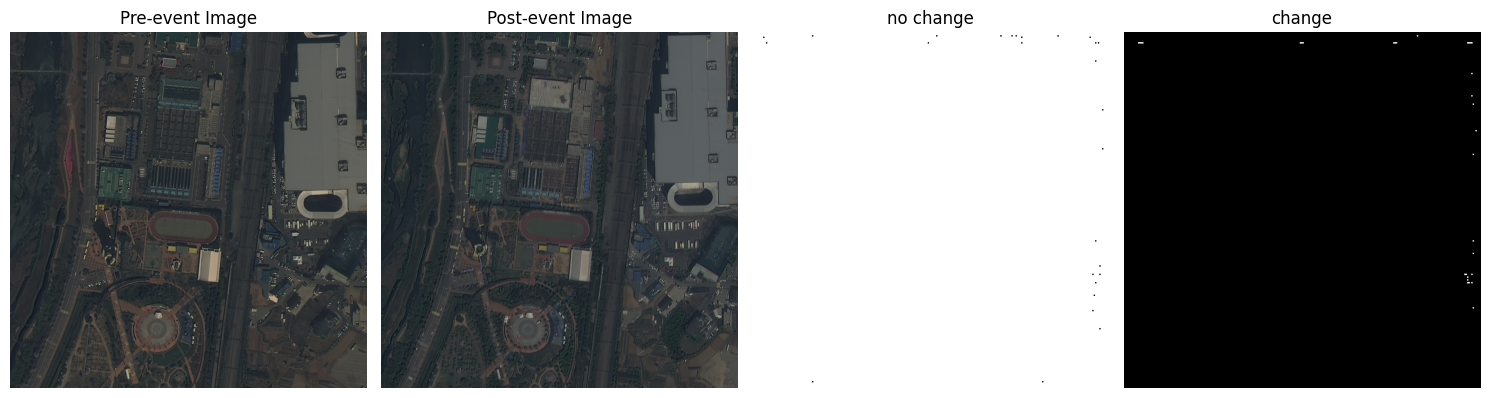

In [9]:
model_path = "/home/dragik/data/FAIR_EO/experiments/s2looking/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("/home/dragik/data/FAIR_EO/s2looking/S2Looking/test/Image1/7.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/s2looking/S2Looking/test/Image2/7.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("/home/dragik/data/FAIR_EO/s2looking/S2Looking/test/Image1/224.png")
image2 = image_loader("/home/dragik/data/FAIR_EO/s2looking/S2Looking/test/Image2/224.png")
fig = model.predict_masks(image1, image2, labels, transform)